# Performance Optimization

Fast code starts with a good algorithm and with measurements, not with tricks. This lesson shows how to find the slow part of a program and how to make it faster.

**After this lesson you can:**

1. Measure code with `timeit` and find hot spots with `cProfile`.
2. Explain why the algorithm (time complexity) matters most.
3. Use built-ins, caching and NumPy vectorisation.
4. Select threads or processes for concurrent work.

## 1. Measure First

> "Premature optimization is the root of all evil." — Donald Knuth

The workflow:

1. Write correct, clear code.
2. Measure: is it too slow for the real use?
3. **Profile** to find the function that takes most of the time.
4. Improve only that part, then measure again.

`cProfile` records how much time each function takes.

In [1]:
import cProfile
import io
import pstats

def load_rows(n):
    return [{"id": i, "price": (i * 37) % 101, "qty": i % 7} for i in range(n)]

def slow_total(rows):
    total = 0.0
    for r in rows:
        total += expensive_tax(r["price"]) * r["qty"]
    return total

def expensive_tax(price):
    return sum(price * 0.0001 for _ in range(50))    # deliberately wasteful

profiler = cProfile.Profile()
profiler.enable()
slow_total(load_rows(20_000))
profiler.disable()
out = io.StringIO()
pstats.Stats(profiler, stream=out).strip_dirs().sort_stats("cumulative").print_stats(6)
print("\n".join(line for line in out.getvalue().splitlines() if line.strip())[:1500])

         1060044 function calls in 0.213 seconds
   Ordered by: cumulative time
   List reduced from 24 to 6 due to restriction <6>
   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.214    0.107 interactiveshell.py:3786(run_code)
        2    0.000    0.000    0.214    0.107 {built-in method builtins.exec}
        1    0.006    0.006    0.195    0.195 2049728390.py:8(slow_total)
    20000    0.009    0.000    0.189    0.000 2049728390.py:14(expensive_tax)
    20000    0.088    0.000    0.181    0.000 {built-in method builtins.sum}
  1020000    0.093    0.000    0.093    0.000 2049728390.py:15(<genexpr>)


The profile shows that almost all time is in `expensive_tax` and the generator inside it. Optimising `load_rows` would not help.

## 2. The Algorithm Matters Most

The **time complexity** describes how the running time grows with the input size $n$. The example finds duplicate values in a list, first with a nested loop ($O(n^2)$), then with a set ($O(n)$).

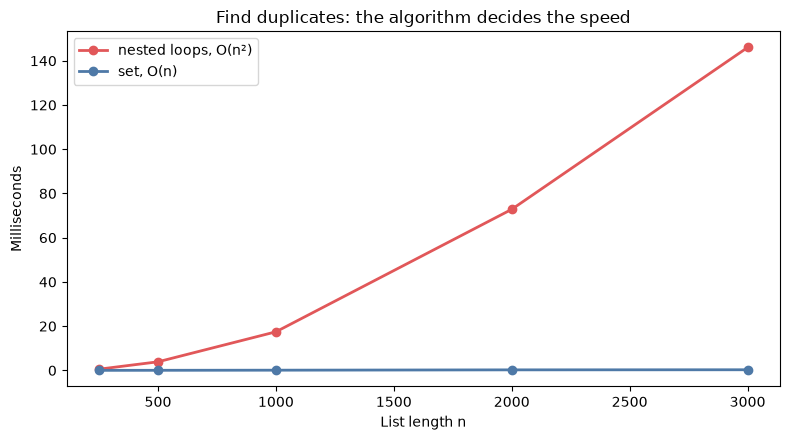

n = 3000: O(n²) 146 ms vs O(n) 0.29 ms -> 512x faster


In [2]:
import random
import time

import matplotlib.pyplot as plt

def duplicates_quadratic(values):
    found = []
    for i in range(len(values)):
        for j in range(i + 1, len(values)):
            if values[i] == values[j] and values[i] not in found:
                found.append(values[i])
    return found

def duplicates_linear(values):
    seen, found = set(), set()
    for v in values:
        if v in seen:
            found.add(v)
        seen.add(v)
    return list(found)

sizes = [250, 500, 1000, 2000, 3000]
t_quad, t_lin = [], []
for n in sizes:
    data = [random.randint(0, n) for _ in range(n)]
    t = time.perf_counter(); a = duplicates_quadratic(data); t_quad.append(time.perf_counter() - t)
    t = time.perf_counter(); b = duplicates_linear(data); t_lin.append(time.perf_counter() - t)
    assert sorted(a) == sorted(b)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, [t * 1000 for t in t_quad], marker="o", lw=2, color="#E15759", label="nested loops, O(n²)")
ax.plot(sizes, [t * 1000 for t in t_lin], marker="o", lw=2, color="#4E79A7", label="set, O(n)")
ax.set(title="Find duplicates: the algorithm decides the speed", xlabel="List length n", ylabel="Milliseconds")
ax.legend()
plt.tight_layout()
plt.show()
print(f"n = {sizes[-1]}: O(n²) {t_quad[-1] * 1000:.0f} ms vs O(n) {t_lin[-1] * 1000:.2f} ms "
      f"-> {t_quad[-1] / t_lin[-1]:,.0f}x faster")

When $n$ doubles, the quadratic version takes about four times longer; the linear version takes about twice as long. No micro-optimisation can compensate for a worse algorithm.

## 3. Built-ins, Caching and Vectorisation

- **Built-in functions** (`sum`, `max`, `sorted`, `str.join`) run in C and are faster than equivalent Python loops.
- **Caching** avoids repeated work (Lesson 15).
- **NumPy vectorisation** applies one operation to a whole array in compiled code (M08).

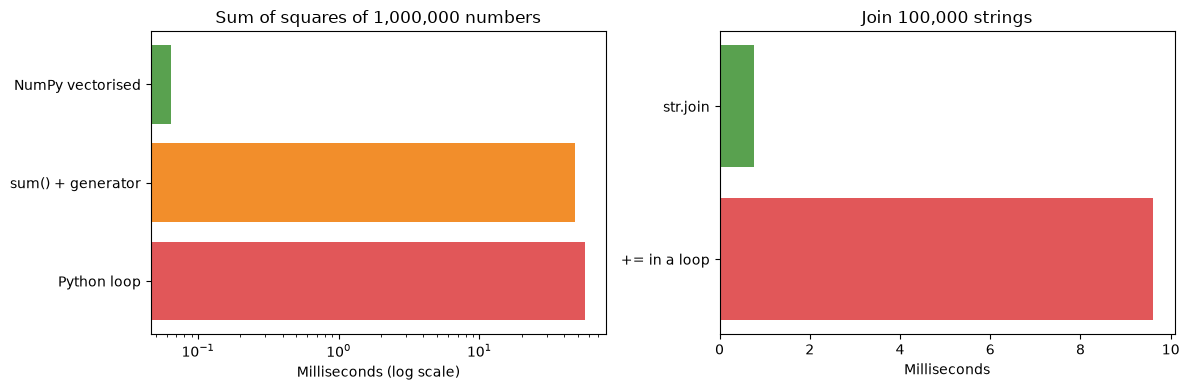

Python loop           56.35 ms (    1x vs loop)
sum() + generator     47.52 ms (    1x vs loop)
NumPy vectorised       0.06 ms (  871x vs loop)
string +=: 9.6 ms | join: 0.8 ms


In [3]:
import timeit

import numpy as np

n = 1_000_000
values = list(range(n))
arr = np.arange(n, dtype=np.float64)

def py_loop():
    total = 0.0
    for v in values:
        total += v * v
    return total

benchmarks = {
    "Python loop": py_loop,
    "sum() + generator": lambda: sum(v * v for v in values),
    "NumPy vectorised": lambda: float(np.dot(arr, arr)),
}
times = {name: min(timeit.repeat(fn, number=3, repeat=3)) / 3 * 1000 for name, fn in benchmarks.items()}

words = ["data"] * 100_000
t_concat = min(timeit.repeat("s = ''\nfor w in words: s += w + ' '", globals=globals(), number=3, repeat=3)) / 3 * 1000
t_join = min(timeit.repeat("' '.join(words)", globals=globals(), number=3, repeat=3)) / 3 * 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.barh(list(times), list(times.values()), color=["#E15759", "#F28E2B", "#59A14F"])
ax1.set(xscale="log", title="Sum of squares of 1,000,000 numbers", xlabel="Milliseconds (log scale)")
ax2.barh(["+= in a loop", "str.join"], [t_concat, t_join], color=["#E15759", "#59A14F"])
ax2.set(title="Join 100,000 strings", xlabel="Milliseconds")
plt.tight_layout()
plt.show()
for name, t in times.items():
    print(f"{name:<18} {t:8.2f} ms ({times['Python loop'] / t:5.0f}x vs loop)")
print(f"string +=: {t_concat:.1f} ms | join: {t_join:.1f} ms")

## 4. Concurrency: Threads vs Processes

- **I/O-bound** work (waiting for networks, disks, databases): use **threads** or `asyncio` (M02). While one thread waits, another runs.
- **CPU-bound** work (computation): in standard CPython, the **Global Interpreter Lock (GIL)** lets only one thread run Python code at a time. Use **processes** to use several CPU cores. Python 3.13 has an experimental build without the GIL (Lesson 18).

The experiment runs 8 tasks of each kind with 1 worker and with 4 workers.

In [4]:
from concurrent.futures import ProcessPoolExecutor, ThreadPoolExecutor

def io_task(_):
    time.sleep(0.2)                       # stands for a network call
    return 1

def cpu_task(_):
    return sum(i * i for i in range(2_000_000))

def run(executor_cls, fn, workers):
    t = time.perf_counter()
    with executor_cls(max_workers=workers) as ex:
        list(ex.map(fn, range(8)))
    return time.perf_counter() - t

results = {
    ("I/O task", "threads"): (run(ThreadPoolExecutor, io_task, 1), run(ThreadPoolExecutor, io_task, 4)),
    ("CPU task", "threads"): (run(ThreadPoolExecutor, cpu_task, 1), run(ThreadPoolExecutor, cpu_task, 4)),
    ("CPU task", "processes"): (run(ProcessPoolExecutor, cpu_task, 1), run(ProcessPoolExecutor, cpu_task, 4)),
}
for (task, kind), (t1, t4) in results.items():
    print(f"{task:<9} {kind:<10} 1 worker {t1:5.2f} s | 4 workers {t4:5.2f} s | speed-up {t1 / t4:4.1f}x")

I/O task  threads    1 worker  1.60 s | 4 workers  0.40 s | speed-up  4.0x
CPU task  threads    1 worker  0.91 s | 4 workers  0.86 s | speed-up  1.1x
CPU task  processes  1 worker  1.06 s | 4 workers  0.36 s | speed-up  2.9x


Threads give a large speed-up for waiting (I/O). For computation, threads give no speed-up because of the GIL, while processes use several cores. (Processes have a start-up cost, so they help only for tasks that take some time.)

*Insight: Optimise in this order: (1) the algorithm and data structure, (2) built-ins and libraries written in C (NumPy, pandas, Polars), (3) caching, (4) concurrency. Measure before and after every change.*

## Real-World Use Case or Analogy

Optimisation is like **reducing the travel time of a delivery company**. First choose the right route (the algorithm); a better route saves hours. Then use the motorway instead of small streets (built-in, compiled code). Do not drive to the warehouse twice for the same parcel (caching). Finally, use more vans for more parcels (concurrency). Polishing the van (micro-optimisations) saves almost nothing.

Data teams follow the same order: a pandas `groupby` replaces a Python loop and runs 100 times faster; a better join strategy in Spark (M13) saves more time than more machines.